# Projet IMA - Exposure Fusion

Adam Safieddine, Victor Coulet

Implementation de l'article *Exposure Fusion* (Mertens, Kautz, Van Reeth). Pour l'instant : pyramides gaussienne et laplacienne, cartes de poids (contraste, saturation, exposition) et premiers tests de fusion naive.

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
plt.rcParams["figure.dpi"] = 70

## Chargement des images

In [2]:
#lecture d'une image en float entre 0 et 1, on la reduit car les photos font 6720x4480
def charger(chemin, largeur=1200):
    img = cv2.imread(chemin)
    h, w = img.shape[:2]
    img = cv2.resize(img, (largeur, int(h * largeur / w)), interpolation=cv2.INTER_AREA)
    return img.astype(np.float32) / 255.0

#affichage avec matplotlib (opencv est en BGR)
def afficher(img, titre="", ax=None):
    if ax is None:
        plt.figure(figsize=(8, 5))
        ax = plt.gca()
    if img.ndim == 3:
        ax.imshow(cv2.cvtColor(np.clip(img, 0, 1).astype(np.float32), cv2.COLOR_BGR2RGB))
    else:
        ax.imshow(img, cmap="gray")
    ax.set_title(titre)
    ax.axis("off")

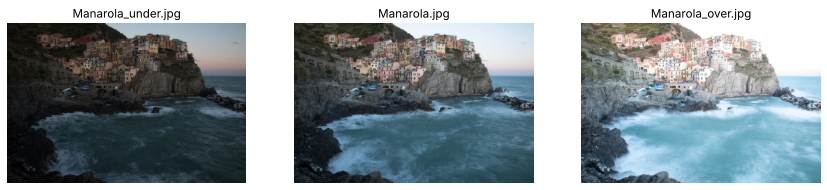

In [3]:
dossier = "Cinque-Terre-Manarola/"
noms = ["Manarola_under.jpg", "Manarola.jpg", "Manarola_over.jpg"]
images = [charger(dossier + n) for n in noms]

fig, axs = plt.subplots(1, 3, figsize=(15, 4))
for img, n, ax in zip(images, noms, axs):
    afficher(img, n, ax)
plt.show()

## 1. Pyramide gaussienne

A chaque niveau on applique un flou gaussien puis on garde un pixel sur deux. C'est ce que fait `cv2.pyrDown`.

G(l+1)[i,j] = somme des w[m,n] * G(l)[2i+m, 2j+n]

In [4]:
#pyramide gaussienne
def pyramide_gauss(img, niveaux):
    G = [img]
    for i in range(niveaux - 1):
        G.append(cv2.pyrDown(G[-1]))
    return G

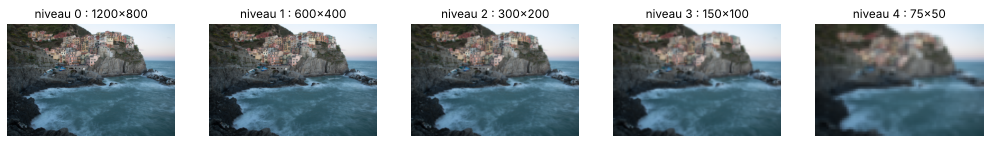

In [5]:
img = images[1]
G = pyramide_gauss(img, 5)

fig, axs = plt.subplots(1, 5, figsize=(18, 3))
for i, g in enumerate(G):
    afficher(g, f"niveau {i} : {g.shape[1]}x{g.shape[0]}", axs[i])
plt.show()

## 2. Pyramide laplacienne

Chaque niveau contient la difference entre un niveau gaussien et la version agrandie du niveau suivant, donc les details perdus par le flou. Le dernier niveau est le residu basse frequence.

L(l) = G(l) - Expand(G(l+1)) et L(N) = G(N)

Il faut travailler en float car les valeurs sont negatives, et donner `dstsize` a `pyrUp` pour les tailles impaires.

In [6]:
#pyramide laplacienne
def pyramide_laplace(img, niveaux):
    G = pyramide_gauss(img.astype(np.float32), niveaux)
    L = []
    for i in range(niveaux - 1):
        taille = (G[i].shape[1], G[i].shape[0])
        L.append(G[i] - cv2.pyrUp(G[i + 1], dstsize=taille))
    L.append(G[-1])
    return L

niveau 0 : min = -0.387  max = 0.545
niveau 1 : min = -0.338  max = 0.306
niveau 2 : min = -0.333  max = 0.253
niveau 3 : min = -0.235  max = 0.290
niveau 4 : min = 0.029  max = 0.987


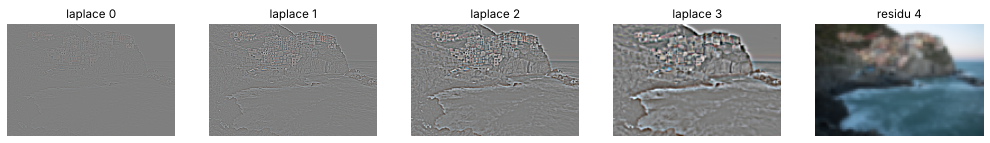

In [7]:
L = pyramide_laplace(img, 5)

fig, axs = plt.subplots(1, 5, figsize=(18, 3))
for i, l in enumerate(L):
    print(f"niveau {i} : min = {l.min():.3f}  max = {l.max():.3f}")
    if i < len(L) - 1:
        afficher(np.clip(l * 3 + 0.5, 0, 1), f"laplace {i}", axs[i])
    else:
        afficher(l, f"residu {i}", axs[i])
plt.show()

Les premiers niveaux sont gris (zones uniformes = 0, recentrees a 0.5) avec seulement les contours. Les couleurs et la luminosite generale sont dans le residu.

## 3. Reconstruction

On remonte la pyramide : G(l) = L(l) + Expand(G(l+1)). La reconstruction est exacte puisqu'on rajoute exactement ce qu'on avait enleve.

In [8]:
#reconstruction a partir de la pyramide laplacienne
def reconstruction(L):
    img = L[-1]
    for niv in reversed(L[:-1]):
        taille = (niv.shape[1], niv.shape[0])
        img = cv2.pyrUp(img, dstsize=taille) + niv
    return img

erreur max : 5.9604645e-08


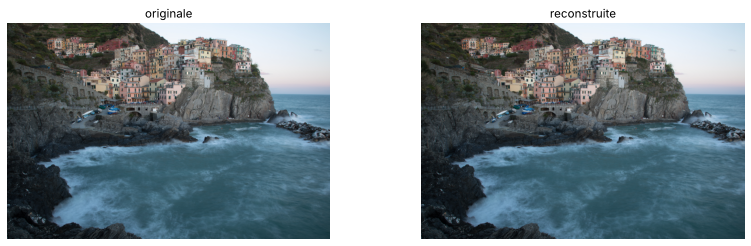

In [9]:
rec = reconstruction(L)
print("erreur max :", np.abs(rec - img).max())

fig, axs = plt.subplots(1, 2, figsize=(14, 4))
afficher(img, "originale", axs[0])
afficher(rec, "reconstruite", axs[1])
plt.show()

## 4. Melange de deux images avec un masque

Test du melange multiresolution avant d'utiliser les vrais poids : moitie gauche de l'image sous-exposee, moitie droite de la surexposee. On melange les pyramides laplaciennes des images avec la pyramide gaussienne du masque, niveau par niveau, puis on reconstruit.

L_R(l) = Gm(l) * L_B(l) + (1 - Gm(l)) * L_A(l)

In [10]:
#melange de A et B niveau par niveau
def melange_pyramide(A, B, masque, niveaux):
    LA = pyramide_laplace(A, niveaux)
    LB = pyramide_laplace(B, niveaux)
    Gm = pyramide_gauss(masque.astype(np.float32), niveaux)
    LR = []
    for la, lb, gm in zip(LA, LB, Gm):
        gm = gm[..., None]
        LR.append(gm * lb + (1 - gm) * la)
    return reconstruction(LR)

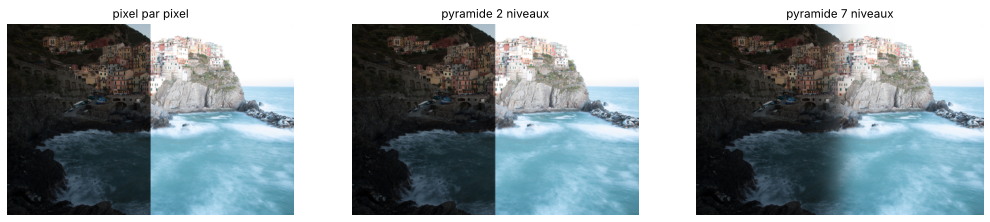

In [11]:
A, B = images[0], images[2]
masque = np.zeros(A.shape[:2], np.float32)
masque[:, A.shape[1] // 2:] = 1

naif = masque[..., None] * B + (1 - masque[..., None]) * A

fig, axs = plt.subplots(1, 3, figsize=(18, 4))
afficher(naif, "pixel par pixel", axs[0])
afficher(melange_pyramide(A, B, masque, 2), "pyramide 2 niveaux", axs[1])
afficher(melange_pyramide(A, B, masque, 7), "pyramide 7 niveaux", axs[2])
plt.show()

Avec plus de niveaux la couture disparait, mais il reste une variation de luminosite tres etalee entre les deux moities, parce que le masque ne tient pas compte du contenu.

## 5. Mesures de qualite (section 3.1 de l'article)

- contraste C : valeur absolue du filtre laplacien sur l'image en niveaux de gris
- saturation S : ecart-type des trois canaux
- exposition E : gaussienne autour de 0.5 de chaque canal, sigma = 0.2, puis produit sur les canaux

In [12]:
#contraste sur l'image en niveaux de gris
def contraste(img):
    gris = cv2.cvtColor(img.astype(np.float32), cv2.COLOR_BGR2GRAY)
    return np.abs(cv2.Laplacian(gris, cv2.CV_32F))

#saturation = ecart type sur les 3 canaux
def saturation(img):
    return np.std(img, axis=2)

#bonne exposition, proche de 0.5
def exposition(img, sigma=0.2):
    g = np.exp(-((img - 0.5) ** 2) / (2 * sigma ** 2))
    return np.prod(g, axis=2)

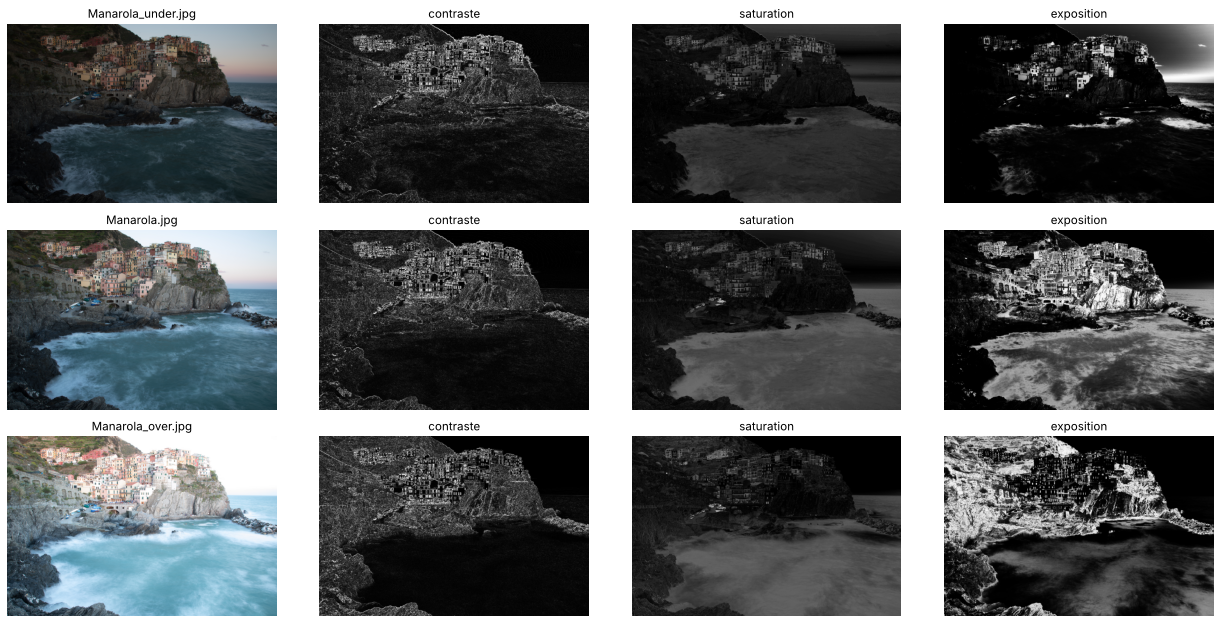

In [13]:
fig, axs = plt.subplots(3, 4, figsize=(18, 9))
for k, (im, n) in enumerate(zip(images, noms)):
    c = contraste(im)
    afficher(im, n, axs[k, 0])
    afficher(np.clip(c / np.percentile(c, 99), 0, 1), "contraste", axs[k, 1])
    afficher(saturation(im) / saturation(im).max(), "saturation", axs[k, 2])
    afficher(exposition(im), "exposition", axs[k, 3])
plt.tight_layout()
plt.show()

Pour l'affichage du contraste on divise par le 99e percentile, sinon quelques pixels tres forts ecrasent tout et l'image parait noire. Ca ne change pas les valeurs utilisees ensuite.

L'exposition est forte dans les zones sombres de l'image surexposee et dans les zones claires de l'image sous-exposee, ce qui est le comportement attendu.

## 6. Cartes de poids

W = C^wc * S^ws * E^we pour chaque image, puis normalisation pour que la somme des poids fasse 1 en chaque pixel. On ajoute un petit epsilon car certains pixels ont un poids nul dans toutes les images (contraste nul dans les zones plates).

In [14]:
#carte de poids d'une image
def carte_poids(img, wc=1, ws=1, we=1):
    return (contraste(img) ** wc) * (saturation(img) ** ws) * (exposition(img) ** we)

#normalisation des poids sur toutes les images
def poids_normalises(images, wc=1, ws=1, we=1, eps=1e-12):
    W = np.array([carte_poids(im, wc, ws, we) for im in images]) + eps
    return W / W.sum(axis=0)

somme des poids : min 0.9999998 max 1.0000001


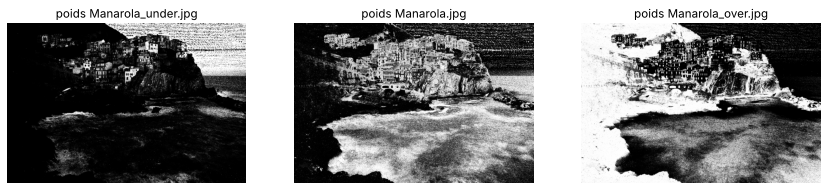

In [15]:
W = poids_normalises(images)
print("somme des poids : min", W.sum(axis=0).min(), "max", W.sum(axis=0).max())

fig, axs = plt.subplots(1, 3, figsize=(15, 4))
for k in range(3):
    afficher(W[k], "poids " + noms[k], axs[k])
plt.show()

## 7. Fusion naive

Premiere fusion directe : moyenne ponderee pixel par pixel, sans pyramide.

R = somme sur k de W_k * I_k

In [16]:
#fusion naive, moyenne ponderee des images
def fusion_naive(images, W):
    R = np.zeros_like(images[0])
    for im, w in zip(images, W):
        R += w[..., None] * im
    return R

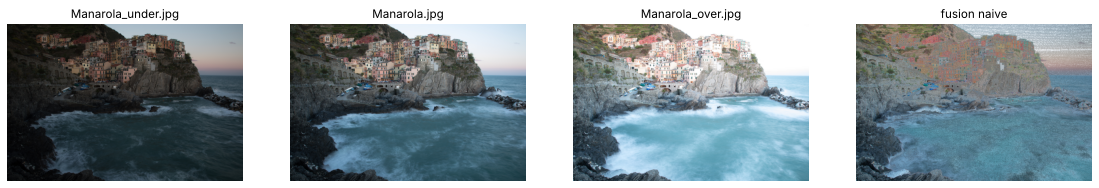

In [17]:
R = fusion_naive(images, W)

fig, axs = plt.subplots(1, 4, figsize=(20, 4))
for im, n, ax in zip(images, noms, axs):
    afficher(im, n, ax)
afficher(R, "fusion naive", axs[3])
plt.show()

### Influence des criteres

On garde un seul critere a la fois pour voir ce que chacun apporte.

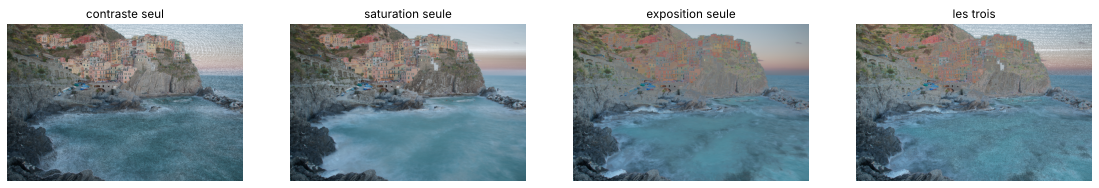

In [18]:
fig, axs = plt.subplots(1, 4, figsize=(20, 4))
tests = [(1, 0, 0, "contraste seul"), (0, 1, 0, "saturation seule"), (0, 0, 1, "exposition seule"), (1, 1, 1, "les trois")]
for (wc, ws, we, titre), ax in zip(tests, axs):
    afficher(fusion_naive(images, poids_normalises(images, wc, ws, we)), titre, ax)
plt.show()

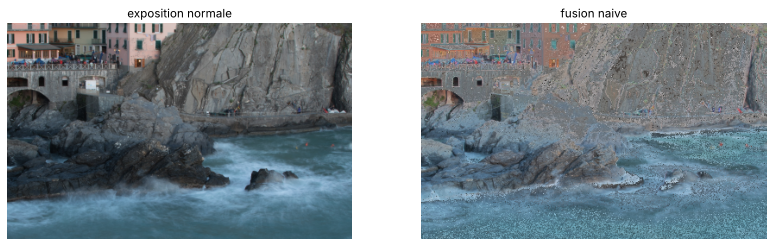

In [19]:
#zoom pour voir les defauts
y, x = 250, 450
fig, axs = plt.subplots(1, 2, figsize=(14, 5))
afficher(images[1][y:y+250, x:x+400], "exposition normale", axs[0])
afficher(R[y:y+250, x:x+400], "fusion naive", axs[1])
plt.show()

La fusion naive recupere bien les zones du ciel et des ombres, mais les poids changent tres vite d'un pixel a l'autre : on voit du bruit et des transitions brutales (coutures, halos). C'est le probleme decrit en 3.2 de l'article, que l'on va corriger avec la fusion multiresolution (pyramide laplacienne des images et pyramide gaussienne des poids).

## 8. Fusion multiresolution

Formule de la section 3.2 : a chaque niveau l on combine la pyramide laplacienne de chaque image avec la pyramide gaussienne de son poids, puis on reconstruit.

L_R(l) = somme sur k de G{W_k}(l) * L{I_k}(l)

Les poids sont de plus en plus lisses quand on descend dans la pyramide, ce qui evite les transitions brutales de la fusion naive.

In [20]:
#fusion multiresolution avec les pyramides
def fusion_pyramide(images, W, niveaux=7):
    LR = None
    for im, w in zip(images, W):
        L = pyramide_laplace(im, niveaux)
        Gw = pyramide_gauss(w.astype(np.float32), niveaux)
        if LR is None:
            LR = [np.zeros_like(l) for l in L]
        for l in range(niveaux):
            LR[l] += Gw[l][..., None] * L[l]
    return reconstruction(LR)

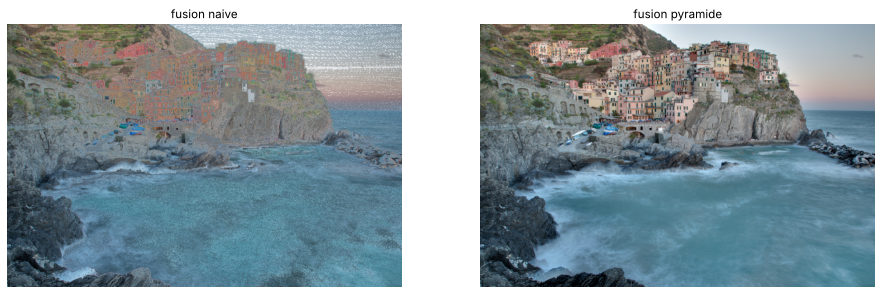

In [21]:
R_pyr = fusion_pyramide(images, W)

fig, axs = plt.subplots(1, 2, figsize=(16, 5))
afficher(R, "fusion naive", axs[0])
afficher(R_pyr, "fusion pyramide", axs[1])
plt.show()

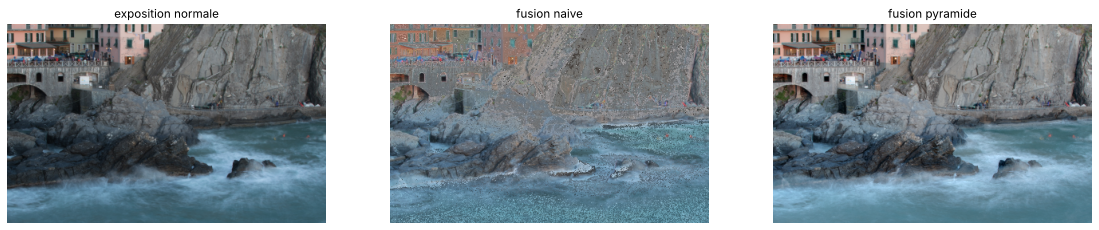

In [22]:
#zoom sur la meme zone que la fusion naive
fig, axs = plt.subplots(1, 3, figsize=(20, 5))
afficher(images[1][y:y+250, x:x+400], "exposition normale", axs[0])
afficher(R[y:y+250, x:x+400], "fusion naive", axs[1])
afficher(R_pyr[y:y+250, x:x+400], "fusion pyramide", axs[2])
plt.show()

Le bruit et les coutures de la fusion naive ont disparu. La fusion pyramide garde le ciel de l'image sous-exposee et les details des rochers de l'image surexposee.

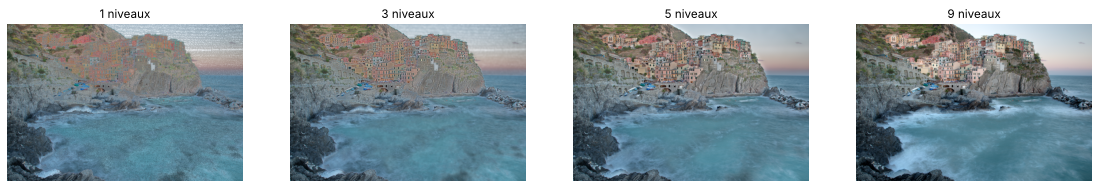

In [23]:
#influence du nombre de niveaux
fig, axs = plt.subplots(1, 4, figsize=(20, 4))
for n, ax in zip([1, 3, 5, 9], axs):
    afficher(fusion_pyramide(images, W, n), f"{n} niveaux", ax)
plt.show()

Avec 1 niveau on retrouve la fusion naive. Plus il y a de niveaux, plus les poids des niveaux grossiers sont lisses et plus le resultat est propre.

## Autres scenes

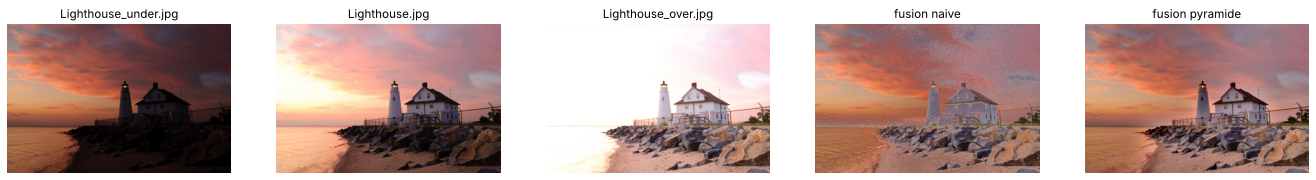

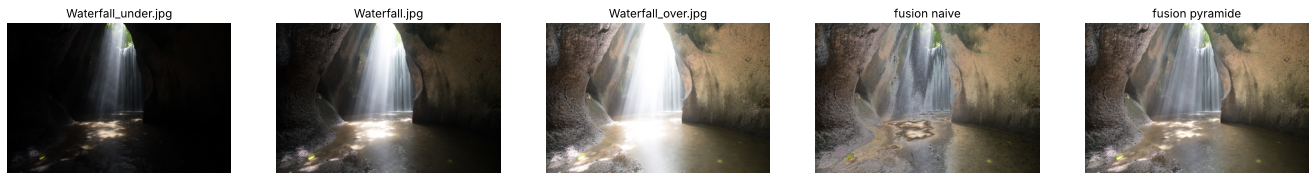

In [24]:
for dossier, noms_s in [("Cove-Point-Lighthouse/", ["Lighthouse_under.jpg", "Lighthouse.jpg", "Lighthouse_over.jpg"]),
                       ("Bali-Tukad-Cepung-Waterfall/", ["Waterfall_under.jpg", "Waterfall.jpg", "Waterfall_over.jpg"])]:
    ims = [charger(dossier + n) for n in noms_s]
    fig, axs = plt.subplots(1, 5, figsize=(24, 4))
    for im, n, ax in zip(ims, noms_s, axs):
        afficher(im, n, ax)
    Wk = poids_normalises(ims)
    afficher(fusion_naive(ims, Wk), "fusion naive", axs[3])
    afficher(fusion_pyramide(ims, Wk), "fusion pyramide", axs[4])
    plt.show()